In [ ]:
from pathlib import Path
import runpy
import pandas as pd
from IPython.display import display, Image # type: ignore

HERE = Path.cwd().resolve()
PROJECT_DIR = HERE if (HERE / "src" / "phase1_analysis.py").exists() else HERE.parent
assert (PROJECT_DIR / "src" / "phase1_analysis.py").exists(), "Open this notebook from the project folder."
print("Project:", PROJECT_DIR)

Project: /Users/ati.rap/Desktop/project_statistics


In [3]:
runpy.run_path(str(PROJECT_DIR / "src" / "phase1_analysis.py"), run_name="__main__")

                                          step  participants
                                        DEMO_L         11933
                                DEMO_L + SLQ_L          8501
                     DEMO_L + SLQ_L + DSQTOT_L          6615
                                       Age 20+          6064
               Adults with valid yes/no DSD010          4779
Adults with positive WTDRD1 among valid yes/no          4775

Adult analysis rows with valid exposure: 4,779
Valid weekday comparisons: 4,702; weekend comparisons: 4,693
Outputs: /Users/ati.rap/Desktop/project_statistics/data/processed/phase1
Figures: /Users/ati.rap/Desktop/project_statistics/figures


{'__name__': '__main__',
 '__doc__': 'Rebuild the NHANES Phase 1 adult sleep and supplement analysis outputs.',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/Users/ati.rap/Desktop/project_statistics/src/phase1_analysis.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__

In [3]:
OUT = PROJECT_DIR / "data" / "processed" / "phase1"
flow = pd.read_csv(OUT / "merge_and_eligibility_flow.csv")
display(flow)

,step,participants
0,DEMO_L,11933
1,DEMO_L + SLQ_L,8501
2,DEMO_L + SLQ_L + DSQTOT_L,6615
3,Age 20+,6064
4,Adults with valid yes/no DSD010,4779
5,Adults with positive WTDRD1 among valid yes/no,4775


In [4]:
prevalence = pd.read_csv(OUT / "supplement_prevalence.csv")
sleep_summary = pd.read_csv(OUT / "sleep_by_supplement_summary.csv")
display(prevalence)
display(sleep_summary.round(3))

,n_valid_yes_no,yes_unweighted_n,prevalence_unweighted_percent,prevalence_WTDRD1_weighted_percent
0,4775,3090,64.712042,60.200539


,outcome,group,n_valid,mean_unweighted_hours,median_hours,q1_hours,q3_hours,mean_WTDRD1_weighted_hours
0,Weekday/workday sleep,No,1648,7.608,8.0,7.0,8.5,7.605
1,Weekday/workday sleep,Yes,3051,7.762,8.0,7.0,8.5,7.714
2,Weekend/non-workday sleep,No,1643,8.227,8.0,7.0,9.0,8.294
3,Weekend/non-workday sleep,Yes,3047,8.228,8.0,7.5,9.0,8.294


In [5]:
frequencies = pd.read_csv(OUT / "sleep_response_frequencies.csv")
display(frequencies)

,measure,response,n,percent_of_valid
0,Weekday/workday,<3 hours (NHANES code 2),28,0.466667
1,Weekday/workday,3 hours,33,0.550000
2,Weekday/workday,3.5 hours,24,0.400000
3,Weekday/workday,4 hours,88,1.466667
4,Weekday/workday,4.5 hours,41,0.683333
5,Weekday/workday,5 hours,204,3.400000
6,Weekday/workday,5.5 hours,122,2.033333
7,Weekday/workday,6 hours,415,6.916667
8,Weekday/workday,6.5 hours,314,5.233333
9,Weekday/workday,7 hours,889,14.816667


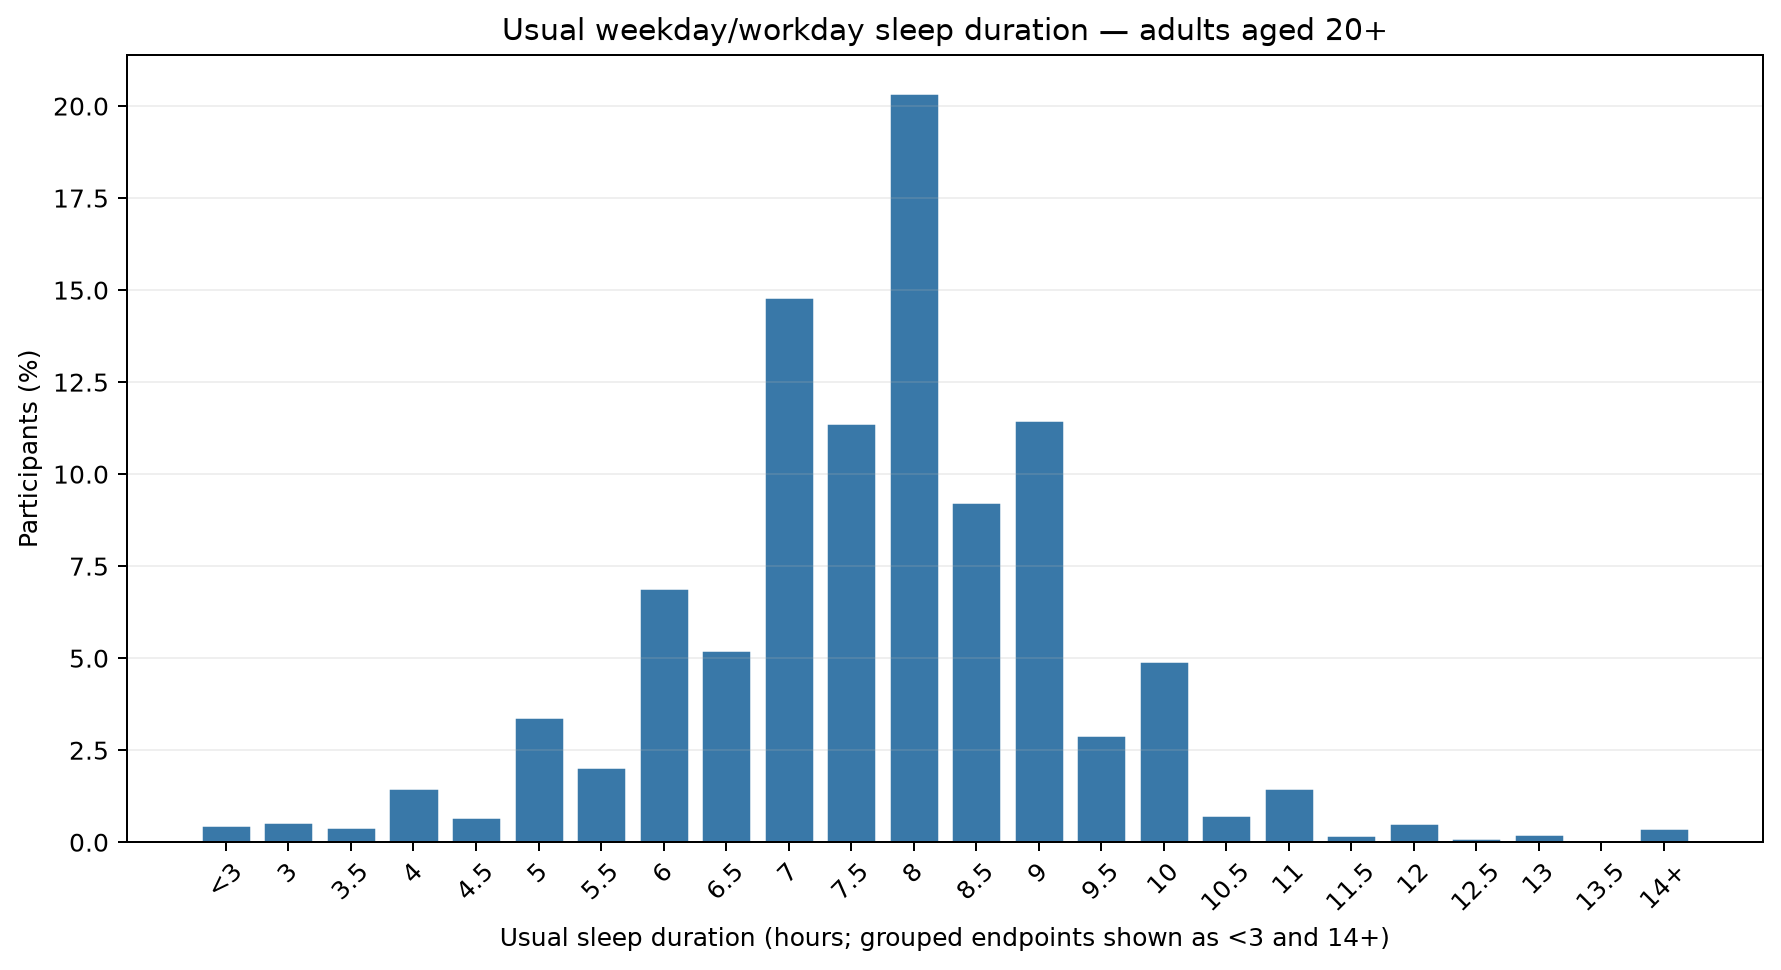

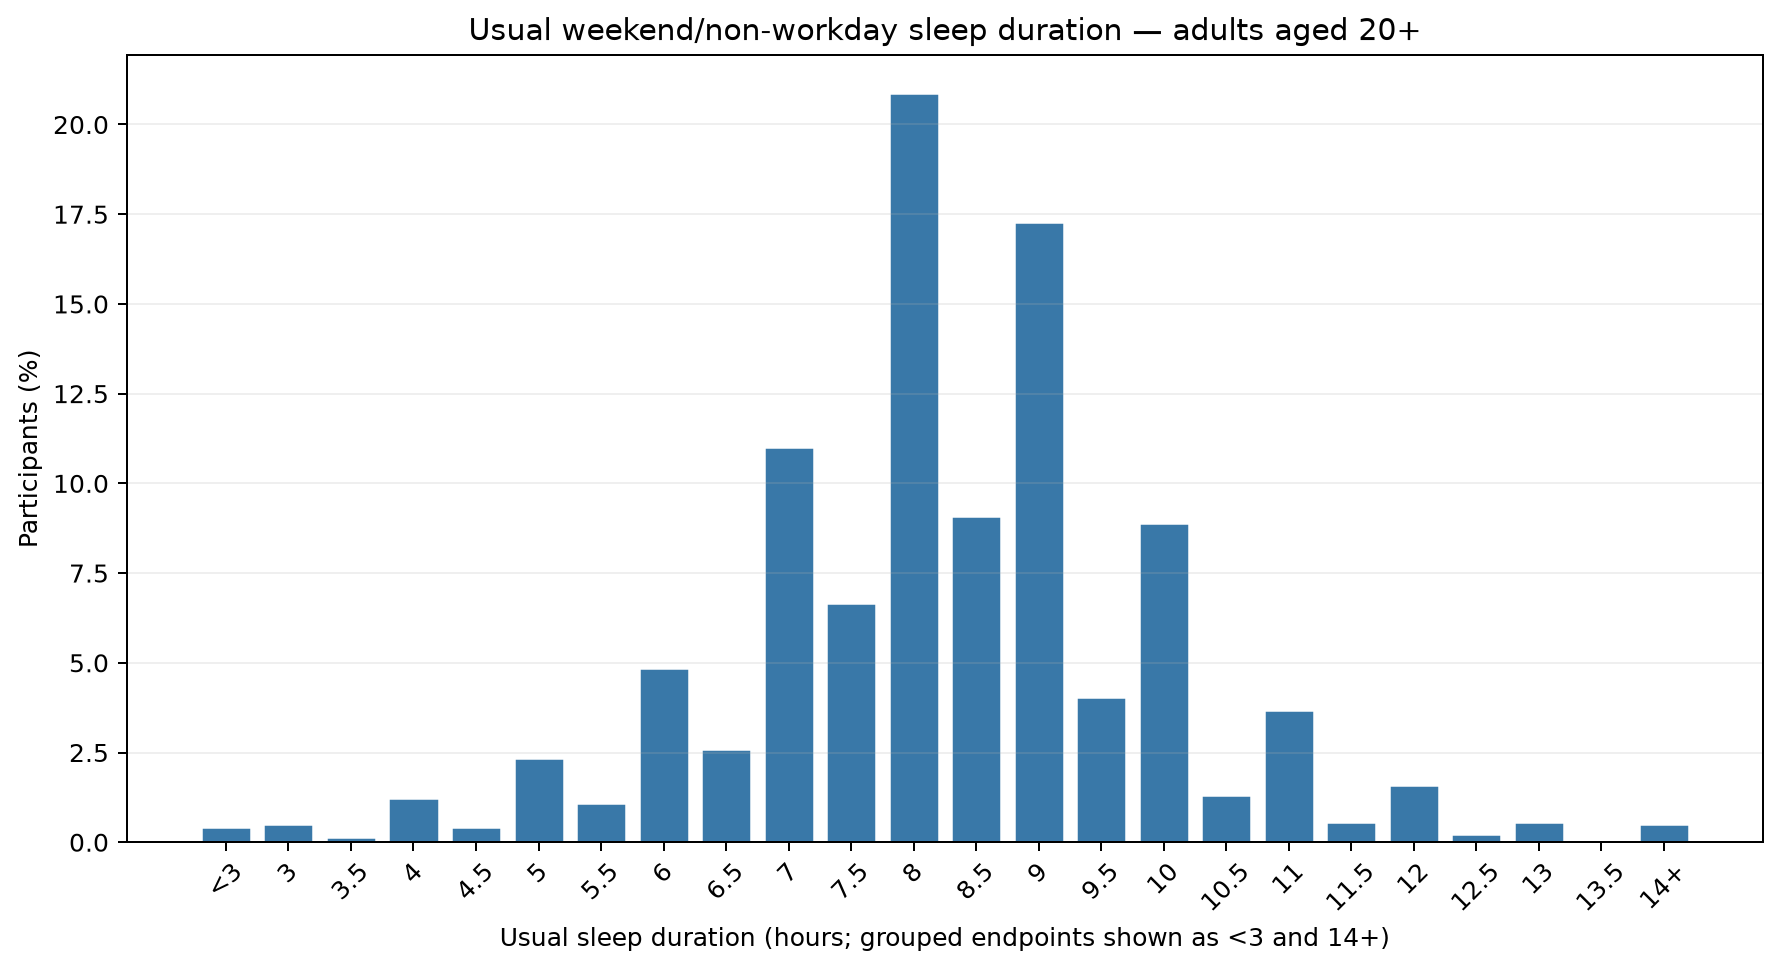

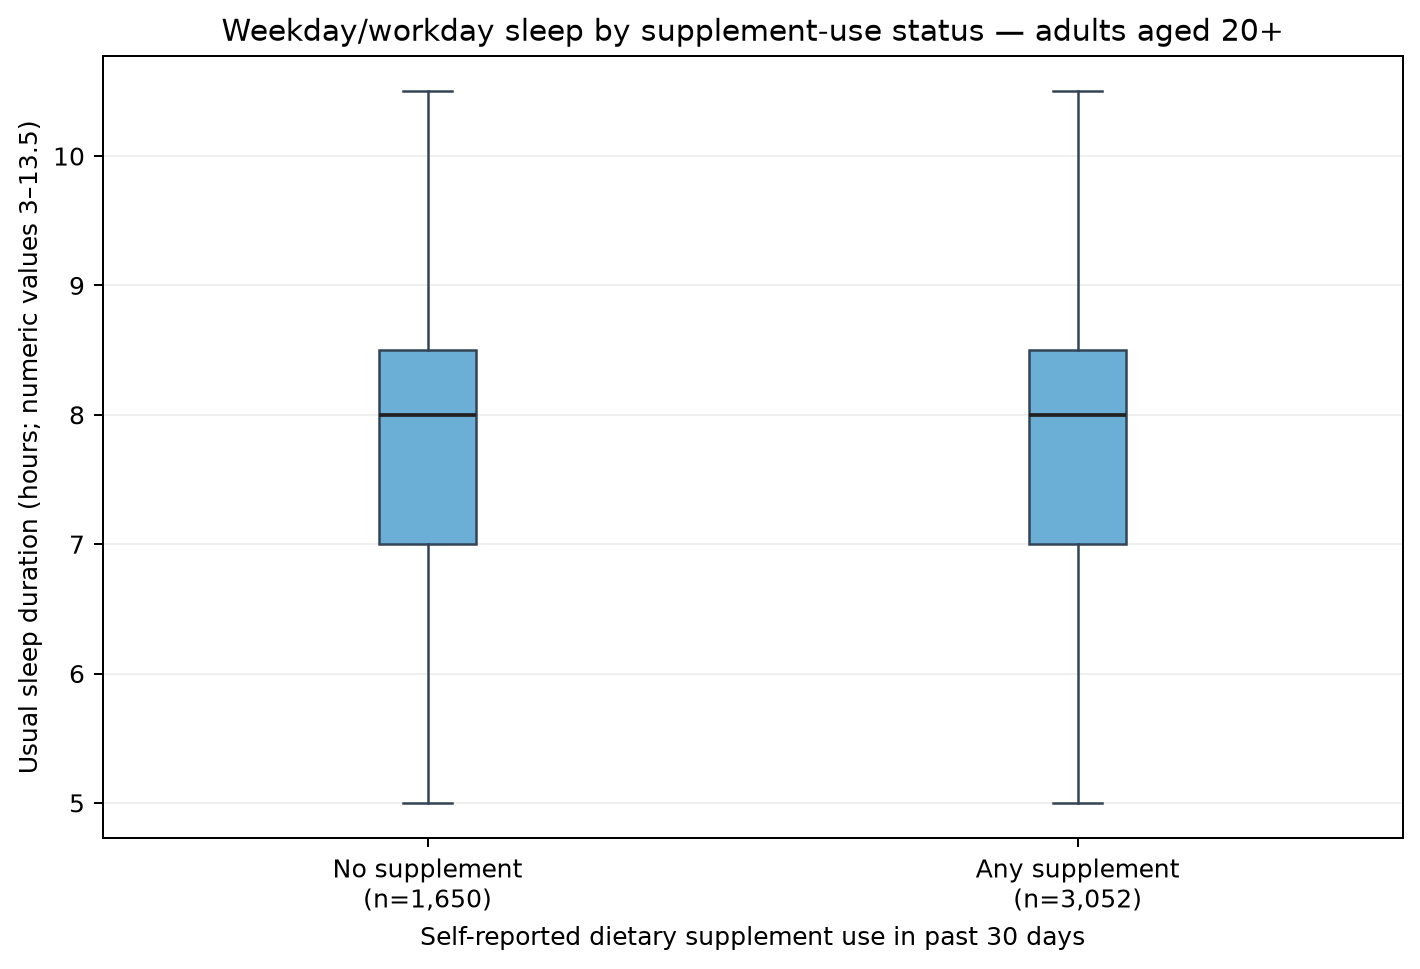

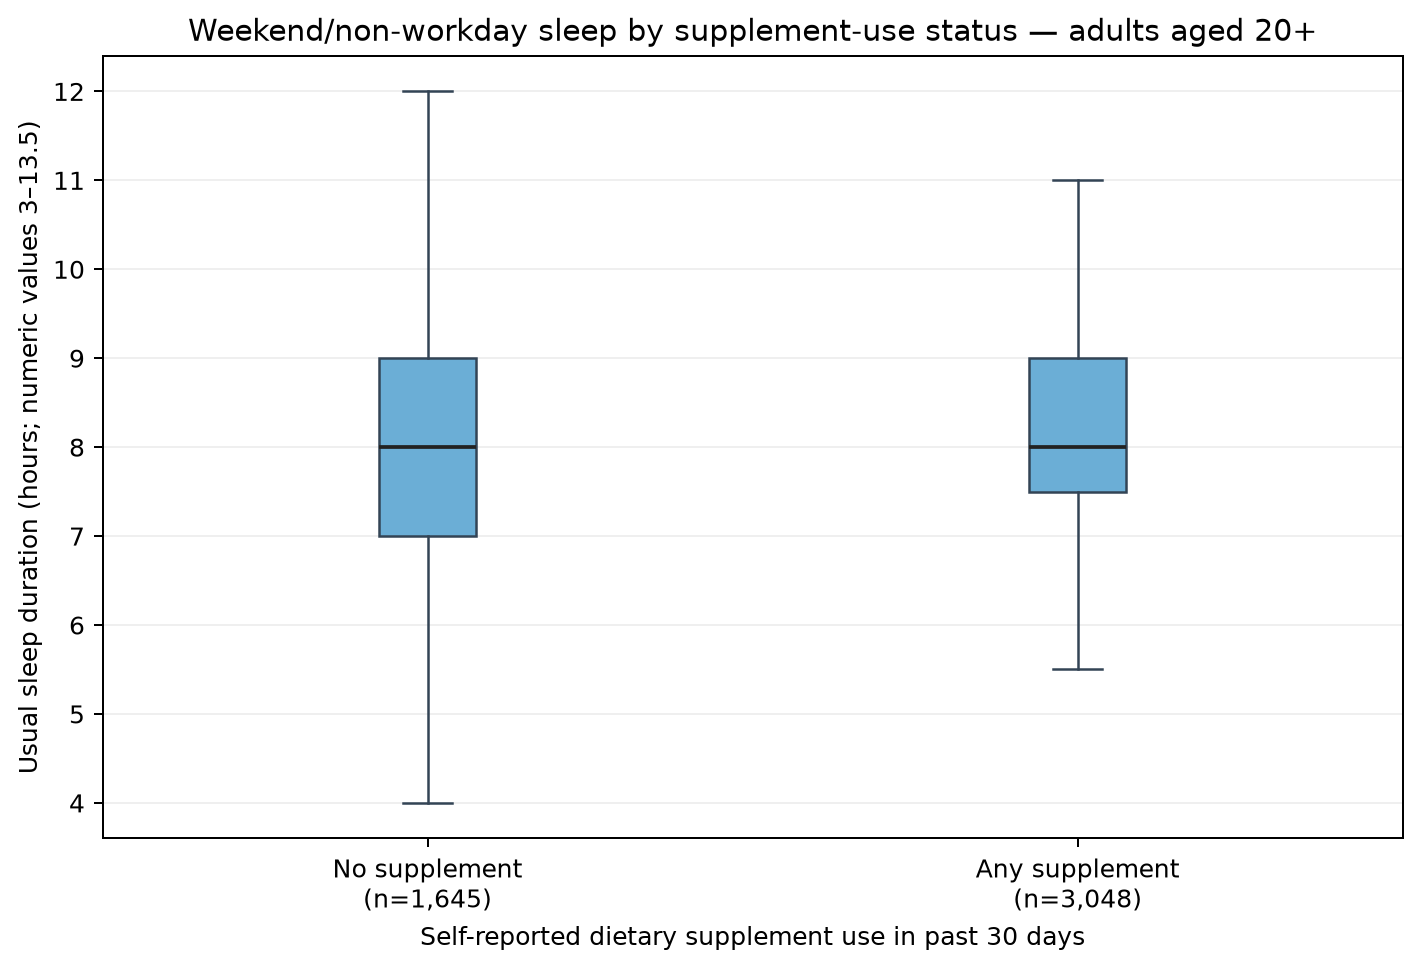

In [6]:
for filename in [
    "fig1_weekday_sleep_distribution.png",
    "fig2_weekend_sleep_distribution.png",
    "fig3_weekday_sleep_by_supplement.png",
    "fig4_weekend_sleep_by_supplement.png",
]:
    display(Image(filename=str(PROJECT_DIR / "figures" / filename)))